# MDST 3D Generative Pipeline — Week 3

## Goal: turn your `.npz` city into a real 3D model in Blender

You have a city as a grid of numbers. This week you'll write
`scripts/export_to_blender.py`, which reads that grid and builds actual 3D
geometry — a terrain mesh, a box for every building, and materials coloring
everything by land use and height.

By the end you'll run one command and get a `.blend` file you can open,
orbit around, and render. **we will work on how to make it look better in future.**

### Read this first

**This notebook is designed to run top to bottom right now**, before you've
written a single line. Every cell either works or tells you clearly what's
missing — nothing crashes just because a file doesn't exist yet. If a cell
does hard-crash on you, that's a bug in the notebook, **so let me know immediately.**
flag it and move on.

Checks in this notebook **report** problems, they don't raise exceptions.
You'll see `[PASS]` / `[FAIL]` lines with hints. A `[FAIL]` is information,
not a wall — keep going and come back to it.

### About running blender "inside" here

`bpy` (Blender's Python API) **only exists inside Blender**. You cannot
`import bpy` in this notebook, and you never will be able to. So the
workflow is:

1. Write the script with `%%writefile` (saves it to `scripts/`)
2. The notebook runs it *through Blender* as a subprocess and shows you any
   errors
3. The notebook renders a preview image and displays it inline

You get a normal edit-run-look loop without leaving Jupyter.


## Part 0 — Setup

Four cells. None of them depend on code you haven't written yet.

In [23]:
import os, sys, subprocess, shutil, ast
from pathlib import Path

_here = Path.cwd().resolve()
for _c in [_here, *_here.parents]:
    if (_c / "citygen" / "city_grid.py").exists():
        os.chdir(_c); break
else:
    raise RuntimeError("Couldn't find the repo root (folder containing citygen/city_grid.py). "
                       "Put this notebook inside your project folder and restart the kernel.")

REPO = Path.cwd()
(REPO / "data").mkdir(exist_ok=True)
(REPO / "scripts").mkdir(exist_ok=True)
print("repo root:", REPO)

repo root: /Users/jemueloppong/Desktop/MDST


In [24]:
def check(label, condition, hint=""):
    """Reports PASS/FAIL. Never raises -- a failure should never stop you."""
    if condition:
        print(f"[PASS] {label}")
    else:
        print(f"[FAIL] {label}")
        if hint:
            for line in hint.strip().splitlines():
                print(f"       {line}")
    return bool(condition)

print("check() ready")

check() ready


### Finding Blender

Blender almost never ends up on your `PATH` automatically, so typing
`blender` in a terminal usually gives **`command not found`**. That's
normal. The cell below looks in the usual install locations for each OS.

If it can't find it, set `BLENDER` by hand in the next cell — everything
else in the notebook will still work.

In [25]:
def find_blender():
    exe = shutil.which("blender")
    if exe:
        return exe
    candidates = [
        "/Applications/Blender.app/Contents/MacOS/Blender",          # macOS
        "/Applications/Blender/Blender.app/Contents/MacOS/Blender",
        "/usr/bin/blender", "/usr/local/bin/blender", "/snap/bin/blender",  # Linux
    ]
    candidates += [str(p) for p in Path("/Applications").glob("Blender*/Contents/MacOS/Blender")]
    # Windows
    for base in (r"C:\Program Files\Blender Foundation", r"C:\Program Files (x86)\Blender Foundation"):
        candidates += [str(p) for p in Path(base).glob("Blender*/blender.exe")] if Path(base).exists() else []
    for c in candidates:
        if Path(c).exists():
            return c
    return None


BLENDER = find_blender()

if BLENDER:
    print("Blender found:", BLENDER)
    try:
        v = subprocess.run([BLENDER, "--version"], capture_output=True, text=True, timeout=120)
        print(v.stdout.strip().splitlines()[0] if v.stdout.strip() else "(no version output)")
    except Exception as e:
        print("found the binary but couldn't run it:", e)
else:
    print("Blender NOT found automatically.")
    print()
    print("Set it manually in the next cell, e.g.:")
    print('  BLENDER = "/Applications/Blender.app/Contents/MacOS/Blender"   # macOS')
    print(r'  BLENDER = r"C:\Program Files\Blender Foundation\Blender 4.2\blender.exe"  # Windows')
    print("  BLENDER = \"/usr/bin/blender\"  # Linux")
    print()
    print("You can still write and syntax-check your script without Blender --")
    print("you just won't be able to run it or see the preview.")

Blender found: /Applications/Blender.app/Contents/MacOS/Blender
Blender 5.2.2 LTS


In [26]:
# If the cell above didn't find Blender, uncomment and edit this line:
# BLENDER = "/Applications/Blender.app/Contents/MacOS/Blender"

print("BLENDER =", BLENDER)

BLENDER = /Applications/Blender.app/Contents/MacOS/Blender


### A city to export

We need a `.npz` to work with. This uses your Week 2 code if it's working, and tells you what to do if it isn't.

In [27]:
CITY_NPZ = REPO / "data" / "week3_city.npz"

if CITY_NPZ.exists():
    print(f"using existing {CITY_NPZ.name}")
else:
    try:
        sys.path.insert(0, str(REPO))
        from citygen import CityGrid, generate_terrain, generate_buildings
        th, iw = generate_terrain(128, archetype="hills", seed=0, relief=1.2)
        bh, lu = generate_buildings(th, iw, archetype="polycentric", num_clusters=3,
                                    density=0.6, cluster_tightness=0.6,
                                    green_amount=0.25, road_continuity=0.7, seed=1)
        CityGrid(size=128, terrain_height=th, is_water=iw,
                 building_height=bh, land_use=lu).save(str(CITY_NPZ))
        print(f"generated {CITY_NPZ.name} using your Week 2 code")
    except Exception as e:
        print(f"Couldn't generate a city from your citygen package: {type(e).__name__}: {e}")
        print()
        print("Fix your Week 2 modules, or drop any .npz city into data/ and set")
        print("CITY_NPZ to point at it. You can keep reading either way.")

check("a city .npz exists to export", CITY_NPZ.exists(),
      "Everything below needs one. See the message above.")

using existing week3_city.npz
[PASS] a city .npz exists to export


True

---

## Part 1 — How the data becomes geometry

Read this before writing anything. It's also the basis for the
documentation you'll write in Part 5.

### What's in the `.npz`

`CityGrid.save()` calls `np.savez_compressed`, which writes five arrays
into one zip-compressed file:

| key | dtype | meaning |
|---|---|---|
| `size` | int | grid is `size x size` |
| `terrain_height` | float32 | ground elevation, normalized 0.0–1.0 |
| `is_water` | bool | `True` where the cell is water |
| `building_height` | float32 | building height, `0.0` where there's none |
| `land_use` | uint8 | 0=empty, 1=building, 2=road, 3=green |

`CityGrid.load()` reads them straight back. Nothing clever — it's just a
labelled bundle of numpy arrays on disk.

### Grid cell → 3D geometry

Two separate meshes get built:

**Terrain** is a grid of vertices. Cell `(y, x)` becomes a vertex at world
position `(x * CELL_SIZE, y * CELL_SIZE, z)`, where `z` comes from
`terrain_height` scaled up by `HEIGHT_SCALE` (the heightmap is 0–1, which
would be invisibly flat at world scale). Water cells get pinned flat at
`z = 0` so lakes read as level surfaces. Then every 2x2 block of
neighbouring vertices gets joined into one quad face — `(size-1)^2` faces
for a `size x size` grid.

**Buildings** are one box per building cell. For a cell at `(y, x)` with
`building_height = h`, you create 4 vertices at the terrain height and 4
more at `terrain_height + h`, then 6 faces to close the box. The boxes are
slightly smaller than a full cell so neighbours don't fuse into one slab.

All of the boxes go into a **single mesh object**, not one object per
building. Thousands of separate Blender objects would make the viewport
unusable; thousands of boxes inside one mesh is completely fine.

### Materials

A Blender mesh can hold several materials in **slots**. Each face carries a
`material_index` pointing at a slot. So "colour by land use" means:
append four materials to the mesh, then set each face's `material_index`
based on that cell's `land_use` value.

Buildings use the same mechanism, but the slot is chosen by **height
percentile** within that city — short buildings grey, mid tan, tall
blue-grey. Using percentiles rather than fixed cutoffs means the colouring
adapts to whatever height range that particular city happens to have.

### Why a subprocess

`bpy` only exists inside Blender's own Python. So the script is run as:

```bash
blender --background --python scripts/export_to_blender.py -- data/city.npz
```

- `--background` runs headless, no GUI
- `--python` runs your script
- `--` separates Blender's arguments from *your* script's arguments.
  **Forgetting it is the single most common mistake** — Blender will try
  to interpret your file path as one of its own options.

### Two constraints that will bite you

1. **`bpy.ops.wm.save_as_mainfile` requires an absolute path.** A relative
   one raises an error. Use `Path(...).resolve()`.
2. **Blender bundles numpy but NOT scipy.** `import scipy` inside Blender
   fails with `ModuleNotFoundError`, and installing it into Blender's
   bundled Python is genuinely painful. Anything running inside Blender
   must stick to numpy and the standard library.


---

## Part 2 — Write the export script

Five TODOs. Everything else is given.

Run the `%%writefile` cell to save the file, then run the checks below it.
Edit, re-run, re-check.

**Keep the function signatures as they are** — `main()` calls them.

In [28]:
%%writefile scripts/export_to_blender.py
"""
Import a saved CityGrid into Blender and build 3D geometry from it.

Must be run with Blender's own Python, not your venv:

    blender --background --python scripts/export_to_blender.py -- data/city.npz

Drop --background to have the GUI open with the result already loaded.

Builds a "Terrain" mesh coloured by land use, and a "Buildings" mesh of one
box per building cell coloured by height tier, then saves a .blend next to
the input .npz.

NOTE: numpy only. Blender does not bundle scipy, so importing it here would
fail with ModuleNotFoundError.
"""
import sys
from pathlib import Path

import bpy
import bmesh
import numpy as np

# Blender passes its own args first, then "--", then ours.
argv = sys.argv[sys.argv.index("--") + 1:] if "--" in sys.argv else []
if not argv:
    raise SystemExit("usage: blender --background --python export_to_blender.py -- <city.npz>")

CITY_PATH = argv[0]

CELL_SIZE = 1.0             # world size of one grid cell
HEIGHT_SCALE = 8.0          # terrain_height is 0-1, so scale it up to be visible
BUILDING_HEIGHT_SCALE = 1.0

# Load citygen/city_grid.py DIRECTLY by file path instead of `from citygen import ...`.
# Importing the citygen package runs citygen/__init__.py, which imports terrain.py
# and buildings.py, and those need scipy -- which doesn't exist inside Blender.
# city_grid.py only needs numpy, so loading it on its own works fine.
import importlib.util  # noqa: E402

_CITY_GRID_PATH = Path(__file__).resolve().parent.parent / "citygen" / "city_grid.py"
_spec = importlib.util.spec_from_file_location("city_grid", _CITY_GRID_PATH)
_city_grid = importlib.util.module_from_spec(_spec)
sys.modules["city_grid"] = _city_grid   # dataclasses looks the module up by name
_spec.loader.exec_module(_city_grid)

CityGrid = _city_grid.CityGrid
LAND_BUILDING = _city_grid.LAND_BUILDING
LAND_GREEN = _city_grid.LAND_GREEN
LAND_ROAD = _city_grid.LAND_ROAD

# name -> (R, G, B), each 0-1. Edit these to change the palette.
COLORS = {
    "ground":          (0.78, 0.72, 0.55),
    "green":           (0.30, 0.55, 0.25),
    "road":            (0.15, 0.15, 0.16),
    "water":           (0.10, 0.35, 0.55),
    "building_short":  (0.55, 0.55, 0.55),
    "building_mid":    (0.70, 0.62, 0.45),
    "building_tall":   (0.35, 0.42, 0.52),
}


# --------------------------------------------------------------------
# GIVEN -- helpers
# --------------------------------------------------------------------

def get_or_create_material(name: str):
    """Fetch a material by name, creating it from COLORS if it doesn't exist."""
    mat = bpy.data.materials.get(name)
    if mat is not None:
        return mat
    mat = bpy.data.materials.new(name)
    mat.use_nodes = True
    bsdf = mat.node_tree.nodes.get("Principled BSDF")
    r, g, b = COLORS[name]
    if bsdf is not None:
        bsdf.inputs["Base Color"].default_value = (r, g, b, 1.0)
    mat.diffuse_color = (r, g, b, 1.0)   # also used by solid viewport shading
    return mat


def clear_scene():
    """Delete everything, so re-running doesn't stack cities on top of each other."""
    bpy.ops.object.select_all(action="SELECT")
    bpy.ops.object.delete(use_global=False)


# --------------------------------------------------------------------
# YOUR CODE -- terrain mesh
# --------------------------------------------------------------------

def build_terrain(city: CityGrid):
    """One vertex per grid cell, joined into quads, coloured by land use."""
    size = city.size
    mesh = bpy.data.meshes.new("TerrainMesh")
    bm = bmesh.new()

    # material slots, in a fixed order -- face.material_index is an index
    # into THIS list, so the order here is what the indices below mean
    slot_names = ["ground", "water", "green", "road"]

    verts = np.empty((size, size), dtype=object)
    for y in range(size):
        for x in range(size):
            # TODO 1: the height of this vertex.
            #   - water cells sit flat at 0.0, so lakes are level
            #   - everything else: city.terrain_height[y, x] * HEIGHT_SCALE
            #     (the heightmap is 0-1; without the scale the terrain is
            #     invisibly flat next to buildings that are 8 units tall)
            if city.is_water[y, x]:
                z = 0.0
            else:
                z = float(city.terrain_height[y, x]) * HEIGHT_SCALE

            verts[y, x] = bm.verts.new((x * CELL_SIZE, y * CELL_SIZE, z))

    for y in range(size - 1):
        for x in range(size - 1):
            # TODO 2: make a quad from this vertex and its three neighbours.
            # bm.faces.new(...) takes a tuple of vertices IN ORDER around the
            # face -- going around the loop, not diagonally across it:
            #   (y, x) -> (y, x+1) -> (y+1, x+1) -> (y+1, x)
            # Listing them in the wrong order gives you a bow-tie face.
            face = bm.faces.new((verts[y, x], verts[y, x + 1],
                                 verts[y + 1, x + 1], verts[y + 1, x]))

            # TODO 3: colour the face by what's on that cell.
            # Set face.material_index to the position of the right name in
            # slot_names, using slot_names.index("...").
            # Priority: water first, then green, then road, else ground.
            if city.is_water[y, x]:
                face.material_index = slot_names.index("water")
            elif city.land_use[y, x] == LAND_GREEN:
                face.material_index = slot_names.index("green")
            elif city.land_use[y, x] == LAND_ROAD:
                face.material_index = slot_names.index("road")
            else:
                face.material_index = slot_names.index("ground")

    bmesh.ops.recalc_face_normals(bm, faces=bm.faces[:])
    bm.to_mesh(mesh)
    bm.free()

    for name in slot_names:
        mesh.materials.append(get_or_create_material(name))

    obj = bpy.data.objects.new("Terrain", mesh)
    bpy.context.collection.objects.link(obj)
    return obj


# --------------------------------------------------------------------
# YOUR CODE -- buildings mesh
# --------------------------------------------------------------------

def build_buildings(city: CityGrid):
    """One box per building cell, all merged into a single mesh object."""
    mesh = bpy.data.meshes.new("BuildingsMesh")
    bm = bmesh.new()

    slot_names = ["building_short", "building_mid", "building_tall"]

    # Height tiers from THIS city's own distribution, so the colouring
    # adapts instead of using fixed cutoffs that would look wrong on a very
    # short or very tall city.
    building_cells = np.argwhere(city.land_use == LAND_BUILDING)
    heights = city.building_height[city.land_use == LAND_BUILDING]
    heights = heights[heights > 0]
    if len(heights) > 0:
        low_cut, high_cut = np.percentile(heights, [40, 75])
    else:
        low_cut, high_cut = 0.0, 0.0

    for y, x in building_cells:
        base_z = float(city.terrain_height[y, x]) * HEIGHT_SCALE
        h = float(city.building_height[y, x]) * BUILDING_HEIGHT_SCALE
        if h <= 0:
            continue

        cx, cy = x * CELL_SIZE, y * CELL_SIZE
        half = CELL_SIZE * 0.4   # < 0.5 leaves a gap so neighbours don't fuse

        # TODO 4: pick the colour tier for this building.
        # h < low_cut            -> "building_short"
        # low_cut <= h < high_cut -> "building_mid"
        # otherwise               -> "building_tall"
        # Again use slot_names.index("...").
        if h < low_cut:
            mat_idx = slot_names.index("building_short")
        elif h < high_cut:
            mat_idx = slot_names.index("building_mid")
        else:
            mat_idx = slot_names.index("building_tall")

        # TODO 5: build the box.
        # `bottom` is given. Make `top` the same four corners but at
        # base_z + h. Keep the SAME corner order in both lists -- the side
        # walls below pair them up by index, so a different order twists
        # the box.
        bottom = [
            bm.verts.new((cx - half, cy - half, base_z)),
            bm.verts.new((cx + half, cy - half, base_z)),
            bm.verts.new((cx + half, cy + half, base_z)),
            bm.verts.new((cx - half, cy + half, base_z)),
        ]
        top = [
            bm.verts.new((cx - half, cy - half, base_z + h)),
            bm.verts.new((cx + half, cy - half, base_z + h)),
            bm.verts.new((cx + half, cy + half, base_z + h)),
            bm.verts.new((cx - half, cy + half, base_z + h)),
        ]

        # GIVEN: close the box. top[::-1] reverses the roof's winding order
        # so its normal points up instead of down.
        new_faces = [bm.faces.new(bottom), bm.faces.new(top[::-1])]
        for i in range(4):
            j = (i + 1) % 4
            new_faces.append(bm.faces.new((bottom[i], bottom[j], top[j], top[i])))

        for face in new_faces:
            face.material_index = mat_idx

    bmesh.ops.recalc_face_normals(bm, faces=bm.faces[:])
    bm.to_mesh(mesh)
    bm.free()

    for name in slot_names:
        mesh.materials.append(get_or_create_material(name))

    obj = bpy.data.objects.new("Buildings", mesh)
    bpy.context.collection.objects.link(obj)
    return obj


# --------------------------------------------------------------------
# GIVEN -- main
# --------------------------------------------------------------------

def main():
    city = CityGrid.load(CITY_PATH)
    print(f"loaded {CITY_PATH}")
    print(f"  stats: {city.stats()}")

    clear_scene()
    build_terrain(city)
    build_buildings(city)

    # .resolve() matters: save_as_mainfile rejects relative paths
    out_path = str(Path(CITY_PATH).with_suffix(".blend").resolve())
    bpy.ops.wm.save_as_mainfile(filepath=out_path)
    print(f"saved {out_path}")


if __name__ == "__main__":
    main()

Overwriting scripts/export_to_blender.py


### Check your script — without Blender

This reads your file as text and inspects its structure. It needs no
Blender and no `bpy`, so it works even if Blender isn't installed — and
it catches the most common mistakes before you spend time launching
Blender.

In [29]:
SCRIPT = REPO / "scripts" / "export_to_blender.py"

print("=" * 60)
if not SCRIPT.exists():
    check("script exists", False, "Run the %%writefile cell above first.")
else:
    src = SCRIPT.read_text()

    syntax_ok = True
    try:
        tree = ast.parse(src)
    except SyntaxError as e:
        syntax_ok = False
        tree = None
        check("file parses as valid Python", False, f"line {e.lineno}: {e.msg}")
    if syntax_ok:
        check("file parses as valid Python", True)

    if tree is not None:
        funcs = {n.name for n in ast.walk(tree) if isinstance(n, ast.FunctionDef)}
        for fn in ("build_terrain", "build_buildings", "main"):
            check(f"{fn}() is defined", fn in funcs,
                  "Did you rename it or delete it? main() calls these by name.")

        n_todo = src.count("YOUR CODE HERE")
        check("all TODOs filled in", n_todo == 0,
              f"{n_todo} 'YOUR CODE HERE' marker(s) left.")

        # find real `...` values via the AST -- a text search would miss
        # `z = ...  # comment` and trip over ellipses inside strings
        ellipsis_lines = sorted({
            n.lineno for n in ast.walk(tree)
            if isinstance(n, ast.Constant) and n.value is Ellipsis
        })
        check("no leftover `...` placeholders", not ellipsis_lines,
              f"still on line(s): {ellipsis_lines}")

        # check actual import statements, not the word appearing in a comment
        imported = set()
        for n in ast.walk(tree):
            if isinstance(n, ast.Import):
                imported.update(a.name.split(".")[0] for a in n.names)
            elif isinstance(n, ast.ImportFrom) and n.module:
                imported.add(n.module.split(".")[0])
        check("no scipy import", "scipy" not in imported,
              "Blender does not bundle scipy -- importing it fails inside Blender.")
        check("uses .resolve() when saving", ".resolve()" in src,
              "save_as_mainfile rejects relative paths.")
print("=" * 60)

[PASS] file parses as valid Python
[PASS] build_terrain() is defined
[PASS] build_buildings() is defined
[PASS] main() is defined
[PASS] all TODOs filled in
[PASS] no leftover `...` placeholders
[PASS] no scipy import
[PASS] uses .resolve() when saving


---

## Part 3 — Run it through Blender

The helper below runs your script in headless Blender and prints whatever
comes back. If your script raises, you'll see the full traceback here —
that's your error message, read it closely.

In [30]:
def run_blender(script_rel, *args, timeout=600):
    """Run a script inside headless Blender. Returns (ok, stdout, stderr)."""
    if not BLENDER:
        print("No Blender configured -- set BLENDER in Part 0 to run this.")
        return False, "", ""

    # Blender resolves a relative --python path against ITS OWN working
    # directory, which is not the one we hand subprocess -- on macOS a
    # relative "scripts/x.py" comes out as "/scripts/x.py" and fails.
    # Always pass an absolute path. Same for our own args, for the same reason.
    def _abs(p):
        p = Path(p)
        return str(p.resolve() if p.is_absolute() else (REPO / p).resolve())

    script_abs = _abs(script_rel)
    if not Path(script_abs).exists():
        print(f"script not found: {script_abs}")
        return False, "", "missing script"

    cmd = [BLENDER, "--background", "--python", script_abs, "--", *[_abs(a) for a in args]]
    print("$", " ".join(cmd), "\n")
    try:
        p = subprocess.run(cmd, capture_output=True, text=True, timeout=timeout, cwd=str(REPO))
    except subprocess.TimeoutExpired:
        print(f"timed out after {timeout}s")
        return False, "", "timeout"

    out = p.stdout or ""
    err = p.stderr or ""
    tail = "\n".join(out.strip().splitlines()[-25:])
    print(tail)

    # Blender reports script errors on STDOUT and still exits 0, so checking
    # only stderr/returncode silently reports success on a failed run.
    combined = out + "\n" + err
    failed = ("Traceback" in combined or "Error:" in combined or p.returncode != 0)
    if failed and err.strip():
        print("\n--- stderr ---")
        print("\n".join(err.strip().splitlines()[-25:]))
    return (not failed), out, err


ok, out, err = run_blender("scripts/export_to_blender.py", CITY_NPZ)
print()
check("export script ran without errors", ok, "Read the traceback above.")
blend_path = CITY_NPZ.with_suffix(".blend")
check(".blend file was created", blend_path.exists(),
      f"expected {blend_path}")

$ /Applications/Blender.app/Contents/MacOS/Blender --background --python /Users/jemueloppong/Desktop/MDST/scripts/export_to_blender.py -- /Users/jemueloppong/Desktop/MDST/data/week3_city.npz 

loaded /Users/jemueloppong/Desktop/MDST/data/week3_city.npz
  stats: {'size': 128, 'water_pct': 0.0, 'building_pct': 20.513916015625, 'green_pct': 15.789794921875, 'road_pct': 16.1865234375, 'max_building_height': 8.33476448059082, 'mean_building_height': 3.709420680999756}
Info: Saved as "week3_city.blend"
saved /Users/jemueloppong/Desktop/MDST/data/week3_city.blend
Blender 5.2.2 LTS (hash d13f752e3b9c built 2026-09-15 01:49:19)

Blender quit

[PASS] export script ran without errors
[PASS] .blend file was created


True

---

## Part 4 — See it

The next cell writes a small **given** render script (no TODOs) that opens
your `.blend`, points a camera at the city and renders a PNG, which then
displays inline below.

It uses Blender's **Workbench** renderer — fast, needs no lighting setup,
shows material colours directly, and behaves consistently across Blender
versions.

If this part misbehaves, it doesn't matter much: your `.blend` already
exists, and you can just open it in Blender directly.

In [31]:
%%writefile scripts/_render_preview.py
"""
GIVEN -- no TODOs. Opens a .blend, frames the scene with a camera, and
renders a PNG with the Workbench engine.

    blender --background --python scripts/_render_preview.py -- in.blend out.png
"""
import sys
from pathlib import Path
import math

import bpy

argv = sys.argv[sys.argv.index("--") + 1:] if "--" in sys.argv else []
if len(argv) < 2:
    raise SystemExit("usage: ... -- <in.blend> <out.png>")

blend_in = str(Path(argv[0]).resolve())
png_out = str(Path(argv[1]).resolve())

bpy.ops.wm.open_mainfile(filepath=blend_in)

# bounding box over all mesh objects, so the camera can frame everything
meshes = [o for o in bpy.data.objects if o.type == "MESH"]
if not meshes:
    raise SystemExit("no mesh objects found in the .blend")

xs, ys, zs = [], [], []
for o in meshes:
    for corner in o.bound_box:
        wc = o.matrix_world @ type(o.location)(corner)
        xs.append(wc.x); ys.append(wc.y); zs.append(wc.z)

cx, cy = (min(xs) + max(xs)) / 2, (min(ys) + max(ys)) / 2
cz = (min(zs) + max(zs)) / 2
extent = max(max(xs) - min(xs), max(ys) - min(ys), 1.0)

cam_data = bpy.data.cameras.new("PreviewCam")
cam = bpy.data.objects.new("PreviewCam", cam_data)
bpy.context.collection.objects.link(cam)

# isometric-ish three-quarter view
dist = extent * 1.5
cam.location = (cx + dist * 0.75, cy - dist * 0.75, cz + dist * 0.75)
cam.rotation_euler = (math.radians(55), 0.0, math.radians(45))
bpy.context.scene.camera = cam

scene = bpy.context.scene
scene.render.engine = "BLENDER_WORKBENCH"   # stable across Blender versions
try:
    scene.display.shading.color_type = "MATERIAL"   # show our material colours
    scene.display.shading.light = "STUDIO"
except Exception as e:
    print("couldn't set workbench shading options:", e)

scene.render.resolution_x = 1200
scene.render.resolution_y = 800
scene.render.film_transparent = False
scene.render.filepath = png_out

bpy.ops.render.render(write_still=True)
print("rendered", png_out)

Overwriting scripts/_render_preview.py


$ /Applications/Blender.app/Contents/MacOS/Blender --background --python /Users/jemueloppong/Desktop/MDST/scripts/_render_preview.py -- /Users/jemueloppong/Desktop/MDST/data/week3_city.blend /Users/jemueloppong/Desktop/MDST/data/week3_preview.png 

00:00.289  blend            | Read blend: "/Users/jemueloppong/Desktop/MDST/data/week3_city.blend"
00:00.492  render           | Saved: '/Users/jemueloppong/Desktop/MDST/data/week3_preview.png'
rendered /Users/jemueloppong/Desktop/MDST/data/week3_preview.png
Blender 5.2.2 LTS (hash d13f752e3b9c built 2026-09-15 01:49:19)

Blender quit
[PASS] preview rendered


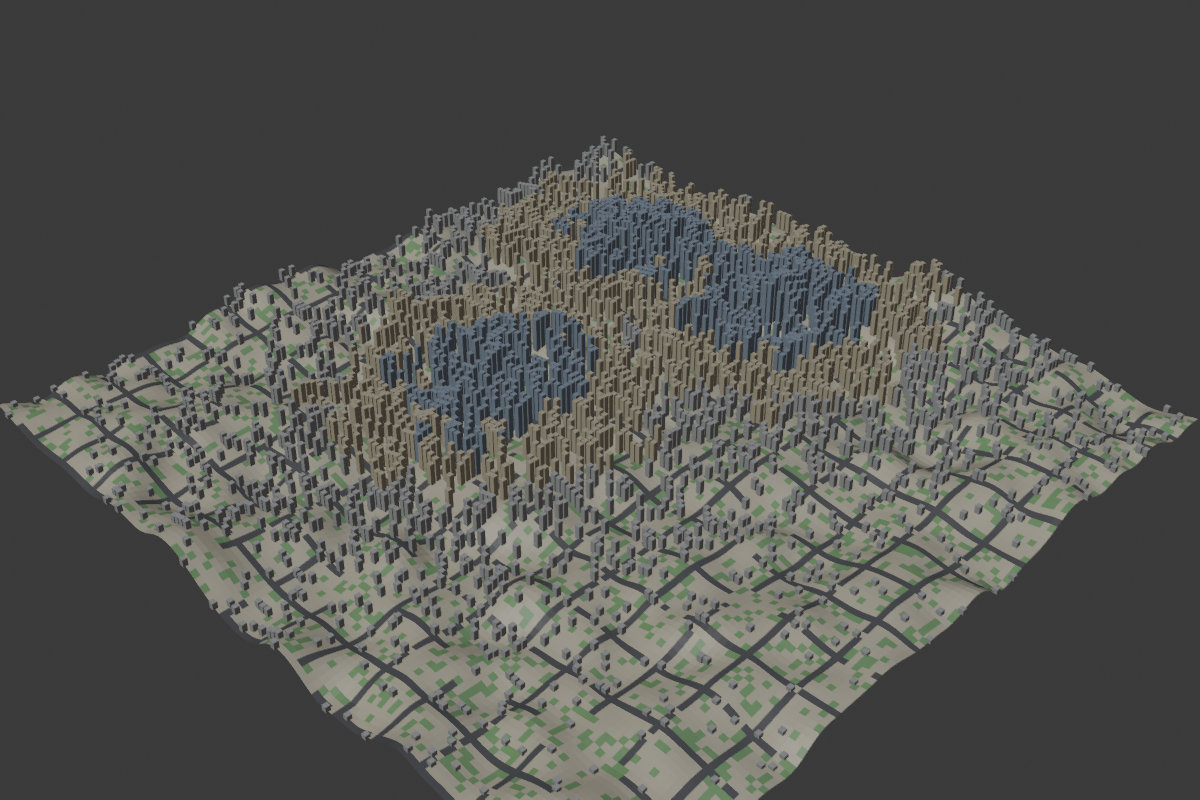

In [32]:
try:
    from IPython.display import Image, display
except ImportError:   # not running under Jupyter
    Image = display = None

preview_png = REPO / "data" / "week3_preview.png"
blend_path = CITY_NPZ.with_suffix(".blend")

if not blend_path.exists():
    print("No .blend yet -- get Part 3 working first.")
else:
    ok_r, _, _ = run_blender("scripts/_render_preview.py", blend_path, preview_png)
    if check("preview rendered", ok_r and preview_png.exists(),
             "Optional step -- if it won't cooperate, just open the .blend in Blender yourself."):
        if display is not None:
            display(Image(filename=str(preview_png)))
        else:
            print("saved to", preview_png)

### Or just open it

```bash
# macOS
/Applications/Blender.app/Contents/MacOS/Blender data/week3_city.blend
```

Or double-click the `.blend` in your file browser.

**To see the colours:** Blender's default **Solid** viewport shading shows
flat grey no matter what materials you set. Use the shading dropdown in the
top-right of the 3D viewport and pick **Material Preview**.

---

## Part 5 — Write the documentation

Write `docs/blender_export.md` explaining how a `.npz` becomes a `.blend`.
Someone joining the team in week 6 should be able to read it and understand
the export without reading the code.

Cover:

1. **The `.npz`** — which arrays, what each means, how `save`/`load` work
2. **Grid → vertices** — how cell `(y, x)` maps to a 3D position, what
   `HEIGHT_SCALE` is for, why water is pinned flat
3. **Vertices → faces** — how quads are formed, why winding order matters
4. **Buildings** — box construction, why `half < 0.5`, why one merged mesh
   instead of thousands of objects
5. **Materials** — slots and `material_index`, why height tiers use
   percentiles rather than fixed cutoffs
6. **Running it** — the full command, what `--background` and `--` do
7. **Gotchas** — absolute path for saving, no scipy in Blender, Material
   Preview for colours

Write it in your own words. If you can't explain a step, that's the step to
go re-read.

In [33]:
docs_dir = REPO / "docs"
docs_dir.mkdir(exist_ok=True)
doc_path = docs_dir / "blender_export.md"

if doc_path.exists():
    print(f"{doc_path} already exists ({len(doc_path.read_text().split())} words) -- not overwriting.")
else:
    doc_path.write_text("""# Blender Export: from .npz to .blend

> Replace each TODO with your own explanation.

## 1. The .npz city file

The .npz file is a compressed archive of the CityGrid data structure, which contains the terrain heightmap, water mask, building heights, and land use information. This file serves as the input for the Blender export script, allowing us to reconstruct the city in 3D.

## 2. Grid cells to 3D vertices

Each cell (y,x) becomes one vertex at (x * CELL_SIZE, y * CELL_SIZE, z), where z is the height of that cell. Water cells sit flat at 0.0, while other cells use city.terrain_height[y, x] * HEIGHT_SCALE to scale the heightmap from 0-1 to a visible range.

## 3. Vertices to faces

Every 2x2 block of neighboring vertices is joined into one quad, giving (size-1)^2 faces. Each face is coloured by the land use of that cell, with water taking priority over green, which takes priority over road, and everything else is ground.

## 4. Buildings

Each building cell becomes a box, with its base at the terrain height and its top at terrain + building_height. The boxes are merged into one mesh, and each is coloured by its height tier (short, mid, tall) based on the city's own distribution of building heights.

## 5. Materials and colors

A mesh holds several materials in slots, and each face's material_index points at one slot, so coloring by land use means setting that index per face. Building colour tiers use percentiles of the city's own building heights, so the colors adapt to the city instead of using fixed cutoffs.

## 6. Running the export

Run blender --background --python scripts/export_to_blender.py -- data/week3_city.npz, which saves a .blend next to the .npz.--background runs Blender without a window and -- separates Blender's own arguments from the script's, so the file path isn't treated as a Blender option

## 7. Gotchas

save_as_mainfile rejects relative paths, so the script uses .resolve() to make the output path absolute. Blender does not bundle scipy, so importing it inside the script fails -- the script loads city_grid.py directly instead of importing the citygen package.

""")
    print(f"created {doc_path} -- fill it in.")

if doc_path.exists():
    body = doc_path.read_text()
    check("documentation has no TODOs left", "TODO" not in body,
          f"{body.count('TODO')} left to write.")

/Users/jemueloppong/Desktop/MDST/docs/blender_export.md already exists (56 words) -- not overwriting.
[FAIL] documentation has no TODOs left
       8 left to write.


---

## Stretch goals

Only after the basics work and the `.blend` opens correctly.

**1. Raise green space.** Give green cells a small height bump
(`z += 0.4`) in `build_terrain` so parks read as slightly raised rather
than painted on.

**2. Merge terraced buildings.** Adjacent short buildings of similar height
could become one continuous block, like row houses — skip the wall between
two cells in the same group. Finding those groups is a connected-components
problem. `scipy.ndimage.label` would do it, **but scipy doesn't exist
inside Blender**, so here's a pure-numpy flood fill:

```python
def connected_components(mask):
    # 4-connectivity connected components, numpy + stdlib only
    h, w = mask.shape
    labels = np.zeros((h, w), dtype=np.int32)
    current = 0
    for sy in range(h):
        for sx in range(w):
            if not mask[sy, sx] or labels[sy, sx]:
                continue
            current += 1
            stack = [(sy, sx)]
            labels[sy, sx] = current
            while stack:                      # explicit stack, not recursion --
                y, x = stack.pop()            # a big region would blow the
                for ny, nx in ((y-1,x),(y+1,x),(y,x-1),(y,x+1)):   # call stack
                    if 0 <= ny < h and 0 <= nx < w and mask[ny,nx] and not labels[ny,nx]:
                        labels[ny,nx] = current
                        stack.append((ny,nx))
    return labels, current
```

**3. A nicer render.** Try the EEVEE engine with real lights instead of
Workbench.

**4. Water as its own surface.** A separate flat transparent plane at
`z = 0` over the water cells.

## Checklist

- [ ] `scripts/export_to_blender.py` written, all structure checks passing
- [ ] It runs in Blender with no traceback
- [ ] A `.blend` is produced and opens with terrain + buildings
- [ ] Colours show up in Material Preview
- [ ] `docs/blender_export.md` written
- [ ] Committed and pushed

## Next week

Back to Python: the model that reads a plain-English description and picks
the generator parameters automatically.
